In [1]:
import ee
import earthaccess
import os
import numpy as np
import pandas as pd
import glob
import matplotlib.pyplot as plt

# Initialize Earth Engine
ee.Authenticate()
ee.Initialize()

# Configuration from your .ipynb
BBOX = [-5.6, 41.0, -4.6, 41.8] # Spain, REHMEDUS Network
START_DATE = "2019-03-01"
END_DATE   = "2020-02-29"
AOI = ee.Geometry.Rectangle(BBOX)

In [2]:
def load_ismn(file_path):
    with open(file_path, 'r') as f:
        header = f.readline().strip()

    parts = header.split()

    try:
        network = parts[1]
        station = parts[2]

        lat = float(parts[3])
        lon = float(parts[4])
        depth_from = float(parts[6])
        depth_to = float(parts[7])
    except:
        return None

    # keep only 0–5 cm
    if not (0.0 <= depth_from <= 0.05 and 0.0 < depth_to <= 0.05):
        return None

    # --- robust read ---
    df = pd.read_csv(
        file_path,
        sep=r'\s+',
        skiprows=1,
        header=None,
        engine='python'
        )

    # handle variable column counts
    if df.shape[1] < 4:
        return None

    df = df.iloc[:, :5]  # keep first 5 cols max
    df.columns = ['date','time','sm','flag','method'][:df.shape[1]]

    # filter good quality
    if 'flag' in df.columns:
        df = df[df['flag'] == 'G']
    else:
        return None

    if len(df) == 0:
        return None

    df['timestamp'] = pd.to_datetime(df['date'] + ' ' + df['time'])

    # USE THIS INSTEAD:
    df['sm'] = pd.to_numeric(df['sm'], errors='coerce')

    df = df.dropna(subset=['sm'])

    df['point_id'] = f"{network}_{station}"
    df['latitude'] = lat
    df['longitude'] = lon

    return df[['point_id','timestamp','sm','latitude','longitude']]

In [3]:
stm_files = glob.glob('Data/Spain/REMEDHUS/*/*.stm', recursive=True)
valid = 0
for f in stm_files:
    out = load_ismn(f)
    if out is not None:
        valid += 1

print("Valid files:", valid)
for f in stm_files[:3]:
    with open(f) as file:
        print(f)
        print(file.readline())

dfs = [load_ismn(f) for f in stm_files]
dfs = [d for d in dfs if d is not None]

ground_truth = pd.concat(dfs, ignore_index=True)

# DAILY AGGREGATION
ground_truth['date'] = ground_truth['timestamp'].dt.floor('D')

ground_truth = ground_truth.groupby(
    ['point_id','date','latitude','longitude']
)['sm'].mean().reset_index()

ground_truth = ground_truth.rename(columns={'date':'timestamp'})

Valid files: 19
Data/Spain/REMEDHUS/Carretoro/REMEDHUS_REMEDHUS_Carretoro_sm_0.000000_0.050000_Stevens-Hydra-Probe_20190301_20200229.stm
REMEDHUS   REMEDHUS   Carretoro       41.26504 -5.38049                 -99.9 0.0000 0.0500 Stevens Hydra Probe

Data/Spain/REMEDHUS/CasaPeriles/REMEDHUS_REMEDHUS_CasaPeriles_sm_0.000000_0.050000_Stevens-Hydra-Probe_20190301_20200229.stm
REMEDHUS   REMEDHUS   Casa_Periles    41.39392 -5.32146                 -99.9 0.0000 0.0500 Stevens Hydra Probe

Data/Spain/REMEDHUS/LasEritas/REMEDHUS_REMEDHUS_LasEritas_sm_0.000000_0.050000_Stevens-Hydra-Probe_20190301_20200229.stm
REMEDHUS   REMEDHUS   Las_Eritas      41.20548 -5.41558                 -99.9 0.0000 0.0500 Stevens Hydra Probe



In [ ]:
def get_s2(aoi, start, end):
    s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
        .filterBounds(aoi).filterDate(start, end) \
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40))
    def mask(img):
        qa = img.select('QA60')
        mask = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
        return img.updateMask(mask)
    def add_idx(img):
        ndvi = img.normalizedDifference(['B8','B4']).rename('NDVI')
        ndwi = img.normalizedDifference(['B8','B11']).rename('NDWI')
        return ee.Image.cat([ndvi, ndwi]).copyProperties(img, ['system:time_start'])
    return s2.map(mask).map(add_idx)

def get_s1(aoi, start, end):
    s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
        .filterBounds(aoi).filterDate(start, end) \
        .filter(ee.Filter.eq('instrumentMode', 'IW'))
    def proc_s1(img):
        ratio = img.select('VV').divide(img.select('VH')).rename('VV_VH_Ratio')
        return img.select(['VV', 'VH']).addBands(ratio).copyProperties(img, ['system:time_start'])
    return s1.map(proc_s1)

def get_lst(aoi, start, end):
    return ee.ImageCollection('MODIS/061/MOD11A1').filterBounds(aoi).filterDate(start, end) \
        .map(lambda img: img.select('LST_Day_1km').multiply(0.02).subtract(273.15)
               .rename('LST').copyProperties(img, ['system:time_start']))

def get_smap(aoi, start, end):
    return ee.ImageCollection('NASA/SMAP/SPL4SMGP/008').filterBounds(aoi).filterDate(start, end) \
        .map(lambda img: img.select('sm_surface').rename('SMAP').copyProperties(img, ['system:time_start']))

def get_era5_plus(aoi, start, end):
    col = ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR").filterBounds(aoi).filterDate(start, end)
    def proc(img):
        return ee.Image.cat([
            img.select("volumetric_soil_water_layer_1").rename("ERA5_SM"),
            img.select("total_precipitation_sum").rename("precip"),
            img.select("surface_net_solar_radiation_sum").rename("ssr"),
            img.select("temperature_2m").subtract(273.15).rename("T_air"),
            img.select("dewpoint_temperature_2m").subtract(273.15).rename("Td_air")
        ]).copyProperties(img, ["system:time_start"])
    return col.map(proc)

def get_lai(aoi, start, end):
    return ee.ImageCollection("MODIS/061/MCD15A3H").filterBounds(aoi).filterDate(start, end) \
        .map(lambda img: img.select("Lai").multiply(0.1).rename("LAI").copyProperties(img, ['system:time_start']))

def get_topo():
    dem = ee.Image("NASA/NASADEM_HGT/001").select('elevation')
    slope = ee.Terrain.slope(dem).rename('slope')
    aspect = ee.Terrain.aspect(dem).rename('aspect')
    return ee.Image.cat([dem.rename('elevation'), slope, aspect])

def get_soil():
    return ee.Image.cat([
        ee.Image("projects/soilgrids-isric/clay_mean").select("clay_0-5cm_mean").rename("clay"),
        ee.Image("projects/soilgrids-isric/sand_mean").select("sand_0-5cm_mean").rename("sand"),
        ee.Image("projects/soilgrids-isric/silt_mean").select("silt_0-5cm_mean").rename("silt")
    ])

# Safety helper functions
def get_daily_safe(col, date, bands):
    next_day = ee.Date(date).advance(1, 'day')
    subset = col.filterDate(date, next_day)
    empty = ee.Image.constant([0] * len(bands)).rename(bands).selfMask()
    return ee.Image(ee.Algorithms.If(subset.size().gt(0), subset.median().select(bands), empty))

def get_window_safe(col, date, bands, days=30):
    window_start = ee.Date(date).advance(-days, 'day')
    subset = col.filterDate(window_start, ee.Date(date).advance(1, 'day'))
    empty = ee.Image.constant([0] * len(bands)).rename(bands).selfMask()
    return ee.Image(ee.Algorithms.If(subset.size().gt(0), subset.median().select(bands), empty))

def get_daily_no_mask(col, date, bands):
    next_day = ee.Date(date).advance(1, 'day')
    subset = col.filterDate(date, next_day)
    # Instead of selfMask(), we provide a constant 0. 
    # This ensures the pixel always "exists" so sampleRegions won't drop it.
    empty = ee.Image.constant([0] * len(bands)).rename(bands)
    return ee.Image(ee.Algorithms.If(subset.size().gt(0), subset.median().select(bands), empty))

def get_window_no_mask(col, date, bands, days=30):
    window_start = ee.Date(date).advance(-days, 'day')
    subset = col.filterDate(window_start, ee.Date(date).advance(1, 'day'))
    empty = ee.Image.constant([0] * len(bands)).rename(bands)
    return ee.Image(ee.Algorithms.If(subset.size().gt(0), subset.median().select(bands), empty))


# %% THE BUILDER
def build_daily_final(date, s2, s1, lst, smap, era5, lai, soil, topo):
    date = ee.Date(date)
    
    # We use unmask() to ensure that if a pixel is cloudy, 
    # it returns 0 instead of 'null'. This prevents row-dropping.
    img = ee.Image.cat([
        get_window_no_mask(s2, date, ['NDVI', 'NDWI']).unmask(0),
        get_window_no_mask(lai, date, ['LAI']).unmask(0),
        get_window_no_mask(s1, date, ['VV','VH','VV_VH_Ratio'], days=12).unmask(0),
        get_daily_no_mask(lst, date, ['LST']).unmask(0),
        get_daily_safe(era5, date, ['ERA5_SM','precip','ssr','T_air','Td_air']).unmask(0),
        get_daily_safe(smap, date, ['SMAP']).unmask(0),
        soil,
        topo
    ])
    
    return img.set('system:time_start', date.millis())

# %% EXECUTION

# 1. Setup Collections once
BUFFER_START = ee.Date(START_DATE).advance(-30, 'day')
s2_col = get_s2(AOI, BUFFER_START, END_DATE)
s1_col = get_s1(AOI, BUFFER_START, END_DATE)
lai_col = get_lai(AOI, BUFFER_START, END_DATE)
lst_col = get_lst(AOI, START_DATE, END_DATE)
smap_col = get_smap(AOI, START_DATE, END_DATE)
era5_col = get_era5_plus(AOI, START_DATE, END_DATE)
soil_img = get_soil()
topo_img = get_topo()

# 2. Date Sequence
dates = ee.List.sequence(0, ee.Date(END_DATE).difference(ee.Date(START_DATE), 'day').subtract(1)).map(
    lambda d: ee.Date(START_DATE).advance(d, 'day')
)

# 3. Final Collection (USING THE ROBUST BUILDER)


# 4. Point Collection
points = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([r.longitude, r.latitude]), {'point_id': r.point_id})
    for r in ground_truth[['point_id','longitude','latitude']].drop_duplicates().itertuples()
])


collection = ee.ImageCollection(
    dates.map(lambda d: build_daily_final(d, s2_col, s1_col, lst_col, smap_col, era5_col, lai_col, soil_img, topo_img))
)

def sample_stations_forced(img):
    ts = img.get('system:time_start')
    return img.sampleRegions(
        collection=points, 
        properties=['point_id'], 
        scale=1000, 
        projection='EPSG:4326',
        tileScale=8,
        geometries=False # Set to False for smaller CSV size, but the key is unmasking above
    ).map(lambda f: f.set('timestamp', ts))

# This will now include every station for every day in your 'dates' list.
training_samples = collection.map(sample_stations_forced).flatten()

# Export
task = ee.batch.Export.table.toDrive(
    collection=training_samples,
    description='remedhus_full_7000_rows',
    fileFormat='CSV'
)
#task.start()

Merge Success: 6871/6889 (99.7%)

--- Zero-Value Gap Analysis ---
LST: 3364 rows are 0 (48.8% cloud/gap)
NDVI: 518 rows are 0 (7.5% cloud/gap)
NDWI: 518 rows are 0 (7.5% cloud/gap)
LAI: 0 rows are 0 (0.0% cloud/gap)
VV: 0 rows are 0 (0.0% cloud/gap)
VH: 0 rows are 0 (0.0% cloud/gap)


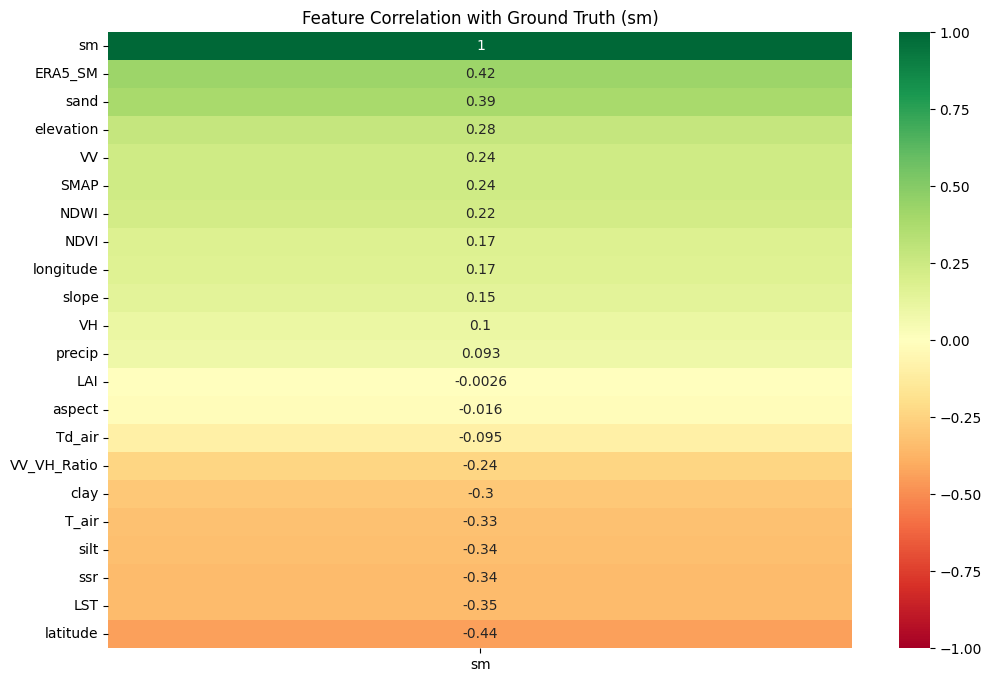

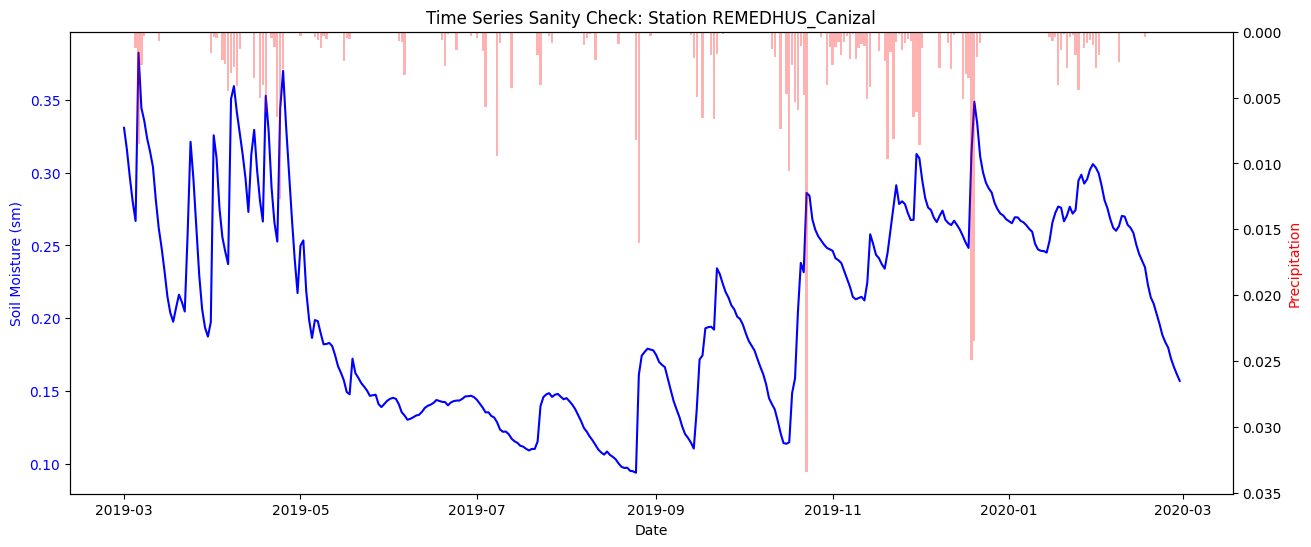


--- Spatial Variation Check ---
           clay        sand   elevation     slope
min  191.000000  445.000000  669.000000  0.211773
max  256.000000  633.000000  899.000000  1.273798
std   19.334694   53.090346   58.812667  0.303630


In [5]:

df_feat = pd.read_csv('Data/Spain/remedhus_full_7000_rows.csv')
df_feat['timestamp'] = pd.to_datetime(df_feat['timestamp'], unit='ms').dt.floor('D')

df = pd.merge(
    ground_truth,
    df_feat,
    on=['point_id','timestamp'],
    how='left'
)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

total_labels = len(ground_truth)
merged_labels = df['NDVI'].notna().sum() # Assuming any matched row has at least some static data
print(f"Merge Success: {merged_labels}/{total_labels} ({(merged_labels/total_labels)*100:.1f}%)")

# 2. Count "Pseudo-Nulls" (The 0s we forced in GEE)
# List the columns that were unmasked to 0
optical_thermal = ['LST', 'NDVI', 'NDWI', 'LAI']
sar = ['VV', 'VH']

print("\n--- Zero-Value Gap Analysis ---")
for col in optical_thermal + sar:
    zero_count = (df[col] == 0).sum()
    print(f"{col}: {zero_count} rows are 0 ({(zero_count/len(df))*100:.1f}% cloud/gap)")
# 2. Feature Correlation (The "Sanity Check")
df_clean = df.copy()

# Ensure we are only looking at columns that exist in the dataframe 
# (optical_thermal and sar must be lists of column names defined earlier)
cols_to_fix = [c for c in optical_thermal + sar if c in df_clean.columns]
df_clean[cols_to_fix] = df_clean[cols_to_fix].replace(0, np.nan)

# Correlation Heatmap
plt.figure(figsize=(12, 8))

# THE FIX: Select only numeric columns to avoid the "MultiPoint" string error
numeric_df = df_clean.select_dtypes(include=[np.number])

# Drop 'timestamp' even if it's numeric (epoch) to keep the heatmap clean
if 'timestamp' in numeric_df.columns:
    numeric_df = numeric_df.drop(columns=['timestamp'])

corr = numeric_df.corr()

sns.heatmap(corr[['sm']].sort_values(by='sm', ascending=False), 
            annot=True, cmap='RdYlGn', vmin=-1, vmax=1)

plt.title("Feature Correlation with Ground Truth (sm)")
plt.show()
# Select the station with the most data
best_station = df['point_id'].value_counts().idxmax()
station_data = df_clean[df_clean['point_id'] == best_station].sort_values('timestamp')

fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.set_xlabel('Date')
ax1.set_ylabel('Soil Moisture (sm)', color='blue')
ax1.plot(station_data['timestamp'], station_data['sm'], color='blue', label='Ground Truth SM')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.set_ylabel('Precipitation', color='red')
ax2.bar(station_data['timestamp'], station_data['precip'], color='red', alpha=0.3, label='Precip (ERA5)')
ax2.invert_yaxis() # Rain comes from the top

plt.title(f"Time Series Sanity Check: Station {best_station}")
plt.show()
static_features = ['clay', 'sand', 'elevation', 'slope']
summary = df.groupby('point_id')[static_features].first()
print("\n--- Spatial Variation Check ---")
print(summary.describe().loc[['min', 'max', 'std']])
# Sort by station and time to ensure rolling windows work
df = df.sort_values(['point_id', 'timestamp'])


In [12]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Feature Engineering (Apply to the WHOLE dataframe first)
df = df.sort_values(['point_id', 'timestamp'])

# --- New: Polarization Ratio (Vital for vegetation correction) ---
df['VV_VH_Ratio'] = df['VV'] / (df['VH'] + 1e-6)

# Rolling Precip (3-day is the "sweet spot" for Spain)
df['precip_3d'] = df.groupby('point_id')['precip'].transform(lambda x: x.rolling(3).sum())

# LST Drying Rate
df['lst_delta'] = df.groupby('point_id')['LST'].transform(lambda x: x.diff())

# 2. Final Prep
XGB_df = df.copy()
# Force 0s to NaN for sensor gaps
cols_to_nan = ['LST', 'NDVI', 'NDWI', 'VV', 'VH', 'VV_VH_Ratio']
XGB_df[cols_to_nan] = XGB_df[cols_to_nan].replace(0, np.nan)

# Delta Anchor
anchor = 'SMAP'
XGB_df['sm_delta'] = XGB_df['sm'] - XGB_df[anchor]

# Remove rows where target or anchor is missing
XGB_df = XGB_df.dropna(subset=['sm_delta', anchor])

# 3. Explicit Feature List (Lean & Mean)
features = [
    'SMAP', 'ERA5_SM', 
    'precip_3d', 'LST', 
    'VV_VH_Ratio', 
    'sand', 'clay', 'elevation', 'T_air', 
    'lst_delta'
]
target = 'sm_delta'

# 4. Station-Based Split
stations = XGB_df['point_id'].unique()
np.random.seed(42)
np.random.shuffle(stations)

split_idx = int(len(stations) * 0.8)
train_stations = stations[:split_idx]
test_stations = stations[split_idx:]

train_data = XGB_df[XGB_df['point_id'].isin(train_stations)]
test_data = XGB_df[XGB_df['point_id'].isin(test_stations)]

X_train = train_data[features].apply(pd.to_numeric, errors='coerce')
X_test = test_data[features].apply(pd.to_numeric, errors='coerce')

y_train = train_data[target]
y_test = test_data[target]
y_test_actual = test_data['sm']

# 5. Train XGBoost (High Regularization to force generalization)
model = xgb.XGBRegressor(
    n_estimators=2000,
    max_depth=4,               # Shallow trees = less overfitting to specific stations
    learning_rate=0.01, 
    subsample=0.7, 
    colsample_bytree=0.7, 
    reg_lambda=10,             # High L2 to smooth out the noise
    early_stopping_rounds=50, 
    missing=np.nan,
    random_state=42
)

model.fit(
    X_train, y_train, 
    eval_set=[(X_test, y_test)], 
    verbose=False
)

# 6. Reconstruct & Evaluate
preds_delta = model.predict(X_test)
final_preds = preds_delta + test_data[anchor].values

rmse = np.sqrt(mean_squared_error(y_test_actual, final_preds))
r2 = r2_score(y_test_actual, final_preds)

print(f"--- Refined Spain Results ---")
print(f"RMSE: {rmse:.4f} m3/m3")
print(f"R2 Score: {r2:.4f}")

--- Refined Spain Results ---
RMSE: 0.0830 m3/m3
R2 Score: 0.3619


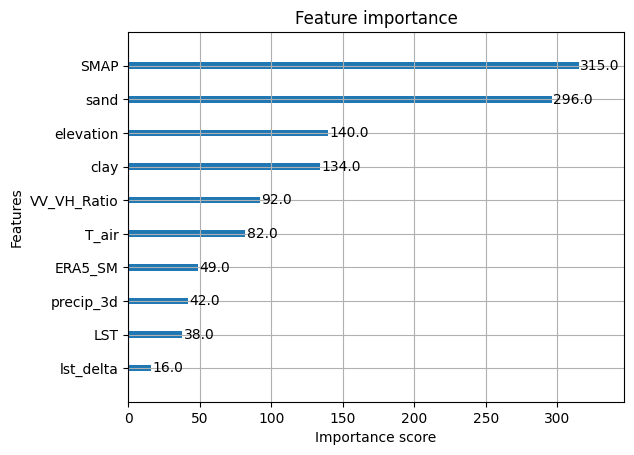

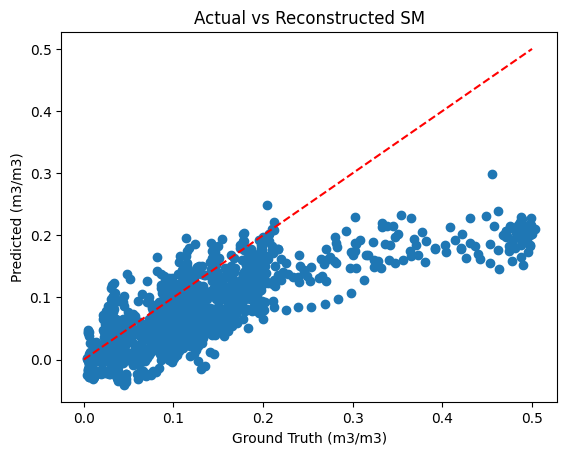

=== DATASET STRUCTURE ===
Total Rows: 6889
Unique Stations: 19

=== THE 'SM' SMOKING GUN (UNITS CHECK) ===
count    6889.000000
mean        0.112010
std         0.098191
min         0.000000
25%         0.029783
50%         0.087696
75%         0.177304
max         0.503000
Name: sm, dtype: float64

=== MISSING DATA (THE GAP CHECK) ===
sm              | Nulls:     0 | Zeros:   138
system:index    | Nulls:    18 | Zeros:     0
ERA5_SM         | Nulls:    18 | Zeros:     0
LAI             | Nulls:    18 | Zeros:     0
LST             | Nulls:    18 | Zeros:  3364
NDVI            | Nulls:    18 | Zeros:   518
NDWI            | Nulls:    18 | Zeros:   518
SMAP            | Nulls:    18 | Zeros:     0
T_air           | Nulls:    18 | Zeros:     0
Td_air          | Nulls:    18 | Zeros:     0
VH              | Nulls:    18 | Zeros:     0
VV              | Nulls:    18 | Zeros:     0
VV_VH_Ratio     | Nulls:    18 | Zeros:     0
aspect          | Nulls:    18 | Zeros:     0
clay            | 

In [13]:
import matplotlib.pyplot as plt
xgb.plot_importance(model, max_num_features=10)
plt.show()
import matplotlib.pyplot as plt
plt.scatter(y_test_actual, final_preds)
plt.plot([0, 0.5], [0, 0.5], '--r')
plt.title("Actual vs Reconstructed SM")
plt.xlabel("Ground Truth (m3/m3)")
plt.ylabel("Predicted (m3/m3)")
plt.show()
import pandas as pd
import numpy as np

def run_brutal_diagnostics(df, target_col='sm'):
    print("=== DATASET STRUCTURE ===")
    print(f"Total Rows: {len(df)}")
    print(f"Unique Stations: {df['point_id'].nunique()}")
    
    print("\n=== THE 'SM' SMOKING GUN (UNITS CHECK) ===")
    # If max is < 0.01, the data is definitely scaled incorrectly
    print(df[target_col].describe())
    
    print("\n=== MISSING DATA (THE GAP CHECK) ===")
    nulls = df.isna().sum()
    zeros = (df == 0).sum()
    for col in df.columns:
        if nulls[col] > 0 or zeros[col] > 0:
            print(f"{col:15} | Nulls: {nulls[col]:5} | Zeros: {zeros[col]:5}")

    print("\n=== FEATURE ALIGNMENT (CORRELATION) ===")
    # Focus on the 'Big Three' - these MUST align
    numeric_df = df.select_dtypes(include=[np.number])
    if all(col in numeric_df.columns for col in [target_col, 'SMAP', 'ERA5_SM']):
        corrs = numeric_df.corr()[target_col].sort_values(ascending=False)
        print("Top 5 Positive Correlations:")
        print(corrs.head(6))
        print("\nTop 5 Negative Correlations:")
        print(corrs.tail(5))

    print("\n=== SPATIAL CONSISTENCY (STATION VARIANCE) ===")
    station_stats = df.groupby('point_id')[target_col].agg(['mean', 'std', 'count']).head(10)
    print("Sample of Station-wise Ground Truth stats:")
    print(station_stats)

    print("\n=== TEMPORAL ALIGNMENT ===")
    print(f"Date Range: {df['timestamp'].min()} to {df['timestamp'].max()}")
    
    # Check if SMAP and sm even move together at one station
    sample_station = df['point_id'].unique()[0]
    sample_df = df[df['point_id'] == sample_station].sort_values('timestamp').head(5)
    print(f"\nSample Time-Series Slice (Station: {sample_station}):")
    print(sample_df[['timestamp', target_col, 'SMAP', 'ERA5_SM']])

# Run it
run_brutal_diagnostics(df)
print(model.get_booster().get_score(importance_type='gain'))